# Part 2 | Spike detection, firing rate & activity map

A neuron firing an **action potential** makes a brief **negative** dip in the
nearby signal. In the filtered trace we detect spikes as **negative threshold
crossings**, with the threshold set at **5 x the noise level**.

We estimate the noise robustly from the **median absolute deviation (MAD)** so the spikes
themselves don't inflate it.

The spikes found here are **multi-unit activity (MUA)**: one electrode hears
several neurons at once. That is fine for *how active* an electrode is (firing
rate, activity map). *How a neuron fires* (regular or bursty) needs single
neurons, so it comes in Part 3, after spike sorting.

## Goal

Detect spikes on the electrodes and describe how much, and where, the culture fires.

By the end of this part you can:
- estimate the noise robustly using the median absolute deviation (MAD) and set a detection threshold
- detect spikes as threshold crossings and show them as a raster
- compute firing rates and map them over the array

> **How the exercises work.** You will meet three kinds of boxes:
> - **✎ Your turn** — one line of code to complete: look for `# TODO` and the
>   obviously-wrong placeholder (e.g. `0.0`). The explanation or worked example
>   just above it shows what you need, and a **check** prints `[OK]` when you
>   got it, or a hint if not.
> - **💬 Discuss:** — a question to discuss with your partner. No code, no check.
> - **🔧 Try it:** — an optional experiment: change a value, re-run, and see what
>   happens. Set it back afterwards.
>
> The full answers live in `mea_helpers.py` if you ever want to peek.

In [1]:
# ========================= YOUR SETTINGS ==============================
GROUP_ID  = 1            # your group number (data exists for groups 1 and 2)
DRUG      = "A"          # config / drug label:  group 1 -> A,B,C,D   group 2 -> A,B
CONDITION = "Baseline"   # "Baseline" or "Drug"

# Path to YOUR group's manifest: the recordings.toml in your group folder on
# the bs-dfs share (the exact path is handed out with the practical), e.g.
#   r"Z:\BEL\Practicals_2026\Group_01\recordings.toml"
MANIFEST  = r"PASTE-THE-PATH-TO-YOUR-recordings.toml"

# The manifest stores full paths to the data, so DATA_ROOT is not used here.
# (Leave as ".": it only matters if your manifest uses relative paths.)
DATA_ROOT = "."
# ======================================================================

import sys; sys.path.append("..")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import mea_helpers as mea

manifest = mea.load_manifest(MANIFEST)
row = mea.find_recording(manifest, GROUP_ID, DRUG, CONDITION)
print("Selected recording:"); print(row)

Selected recording:
UID                        G05_A_Baseline
GroupID                                 5
Chip                               maxtwo
Drug                                    A
Conditions                       Baseline
Well                                    0
raw_files       raw/G05_A_Baseline.raw.h5
sorted_files        sorted/G05_A_Baseline
Name: 0, dtype: object


## 1. Load a manageable set of channels (detecting on all is slow)

In [2]:
recording = mea.open_recording(row, data_root=DATA_ROOT)
fs = recording.get_sampling_frequency()

# the 20 electrodes with the most online-detected spikes (Part 0): quick to find,
# so we only read the raw data of these 20, not of all ~1000
online = mea.load_online_spikes(row, data_root=DATA_ROOT)
active_ids = online["channel"].value_counts().index[:20].tolist()

t, raw = mea.get_traces(recording, 0, 10, channel_ids=active_ids)
filt = mea.bandpass_filter(raw, fs)
trace = filt[:, 0]        # one channel to play with
print("Using", len(active_ids), "channels; 'trace' is channel", active_ids[0])

Using 20 channels; 'trace' is channel 311


## 2. Estimating the noise level using median absolute deviation (MAD)

To call a threshold-crossing event a spike, we first need to know how large the **noise** is.
In Part 1 you measured it as the **RMS** — and saw its catch: the spikes
themselves inflate it. Here we use an estimate that ignores them.

Remember: `trace` is the **filtered** signal (300–3000 Hz) of the most active
channel, 10 s long, in µV.

### Look first — what is in `trace`?

On the left, the first second of `trace`; on the right, a histogram of **all**
its values (10 s), turned on its side so both share the same µV axis. Note the
log scale of the counts.

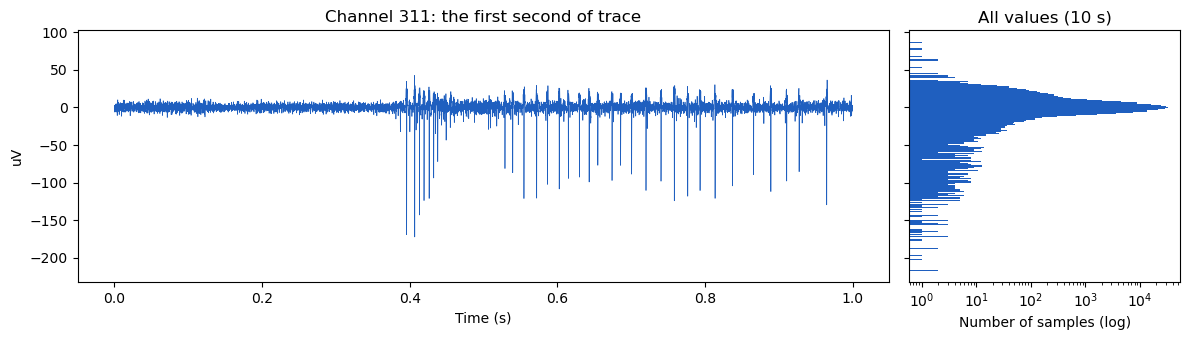

In [3]:
fig, (ax_t, ax_h) = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True, width_ratios=[3, 1])
first_s = t < 1.0                                               # the first second
ax_t.plot(t[first_s], trace[first_s], color="#1f5fbf", lw=0.5)
ax_t.set_xlabel("Time (s)"); ax_t.set_ylabel("uV")
ax_t.set_title(f"Channel {active_ids[0]}: the first second of trace")

ax_h.hist(trace, bins=200, orientation="horizontal", color="#1f5fbf")
ax_h.set_xscale("log")
ax_h.set_xlabel("Number of samples (log)")
ax_h.set_title("All values (10 s)")
plt.tight_layout(); plt.show()

> Almost all samples form a narrow, symmetric **bell around 0**: that is the
> noise, the band the trace wiggles in all the time. The long **tail downward**
> are the few samples inside spikes: the sharp dips in the trace. The
> RMS averages *all* squared values, so the tail pulls it up. The **median** of
> `|trace|` only asks "where is the middle sample?", and the middle sample is a
> noise sample — however large the spikes are.

### Worked example — where does 0.6745 come from?

The median of `|trace|` (the **median absolute deviation**, MAD) is *not* the
noise standard deviation itself. To find the conversion, simulate pure noise
whose SD we know (5 µV) and take the median of its absolute values:

In [4]:
rng = np.random.default_rng(0)
noise_sim = rng.normal(0, 5, size=100_000)       # pure Gaussian noise, SD = 5 uV

mad_sim = np.median(np.abs(noise_sim))
print(f"median(|noise|) = {mad_sim:.2f} uV")
print(f"median(|noise|) / SD = {mad_sim / 5:.4f}")

median(|noise|) = 3.37 uV
median(|noise|) / SD = 0.6747


For Gaussian noise the MAD is always **0.6745 x the SD**. So dividing the MAD
by 0.6745 gives back the SD:

$$\sigma = \frac{\text{median}(|\text{trace}|)}{0.6745}$$

### ✎ Your turn — estimate the noise of `trace`

Write the formula above in code (`np.median` and `np.abs` are all you need).

In [5]:
# TODO: replace the 0.0 with the noise estimate (sigma) of `trace`, in uV.
sigma = 0.0

print(f"noise sigma = {sigma:.2f} uV")
mea.check(sigma, mea.noise_std_mad(trace),
          hint="sigma = np.median(np.abs(trace)) / 0.6745")

noise sigma = 0.00 uV
[X] not quite yet.
   hint: sigma = np.median(np.abs(trace)) / 0.6745
   you got: 0.0
   expected ~ 3.769641068394025


False

### Worked example — RMS vs MAD

How different are the two estimates? First on `trace` (an active electrode)...

In [6]:
rms_trace = np.sqrt(np.mean(trace ** 2))
print(f"RMS = {rms_trace:.1f} uV,  MAD sigma = {mea.noise_std_mad(trace):.1f} uV")

RMS = 6.0 uV,  MAD sigma = 3.8 uV


...then on **every** electrode (2 s each), coloured by how active it is
(online-detected spikes, Part 0):

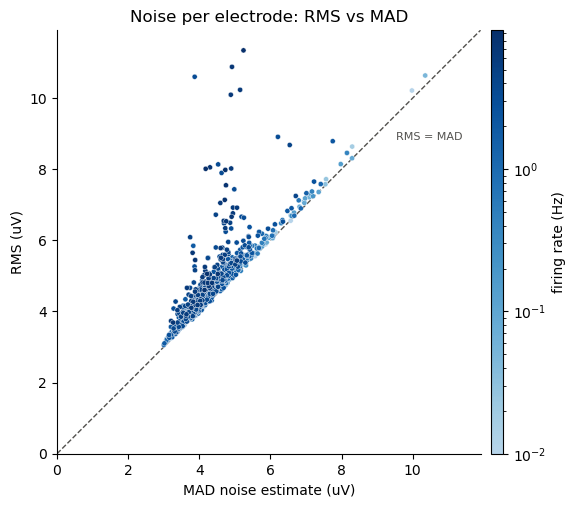

electrode 822: RMS 10.6 uV, MAD 3.9 uV -> a 5x threshold of -53 uV (RMS) vs -19 uV (MAD)


In [7]:
noise = mea.channel_noise(recording, t_start=0, duration=2.0)     # rms_uv, mad_uv
rate = online.groupby("channel").size() / (recording.get_num_frames() / fs)

mea.plot_noise_comparison(noise, rate)
plt.title("Noise per electrode: RMS vs MAD"); plt.show()

worst = (noise["rms_uv"] / noise["mad_uv"]).idxmax()
print(f"electrode {worst}: RMS {noise.loc[worst, 'rms_uv']:.1f} uV, "
      f"MAD {noise.loc[worst, 'mad_uv']:.1f} uV -> a 5x threshold of "
      f"{-5 * noise.loc[worst, 'rms_uv']:.0f} uV (RMS) vs {-5 * noise.loc[worst, 'mad_uv']:.0f} uV (MAD)")

> **💬 Discuss:** quiet electrodes sit on the diagonal (RMS = MAD). Which
> electrodes rise above it, and why? On the worst electrode, which spikes would
> a threshold of 5 x RMS miss that 5 x MAD catches? This is why we detect with
> the MAD.

## 3. The threshold, and how many samples cross it

A spike is a large **negative** deflection, much larger than the noise. We call
everything below **−5 x sigma** a spike. Why 5? Pure noise almost never
reaches 5 SDs, so (nearly) all crossings are real spikes.

### ✎ Your turn (a) — set the threshold

Set `threshold` to minus five times your `sigma`. The plot below shows 100 ms
of `trace` around its largest spike, with your threshold as a dashed line:
it should sit **below** the noise band, so only spikes reach it.

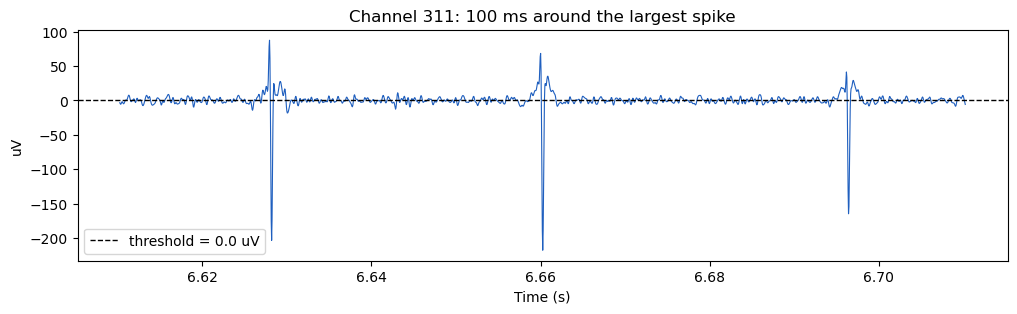

[X] not quite yet.
   hint: minus five times sigma: threshold = -5 * sigma
   you got: 0.0
   expected ~ -18.848205341970125


False

In [8]:
# TODO: replace the 0.0 with the detection threshold (uV) - it must be NEGATIVE.
threshold = 0.0

i0 = np.argmin(trace)                                  # the largest spike
win = slice(max(i0 - int(0.05 * fs), 0), i0 + int(0.05 * fs))
plt.figure(figsize=(12, 3))
plt.plot(t[win], trace[win], color="#1f5fbf", lw=0.8)
plt.axhline(threshold, color="k", ls="--", lw=1, label=f"threshold = {threshold:.1f} uV")
plt.xlabel("Time (s)"); plt.ylabel("uV"); plt.legend(loc="lower left")
plt.title(f"Channel {active_ids[0]}: 100 ms around the largest spike"); plt.show()

mea.check(threshold, -5 * mea.noise_std_mad(trace),
          hint="minus five times sigma: threshold = -5 * sigma")

### ✎ Your turn (b) — samples or spikes?

`np.sum(trace < threshold)` counts the **samples** below the threshold. But a
spike lasts several samples (at 20 kHz, one sample = 0.05 ms), so this is not
the number of spikes. A spike starts where the trace **crosses** the threshold
going down: the sample before is still above it, this sample is below it.

```
trace[:-1] >= threshold      the previous sample is above ...
trace[1:]  <  threshold      ... and this one is below
```

Count the samples where **both** are true (combine them with `&`).

In [9]:
n_below = np.sum(trace < threshold)

# TODO: replace the 0 with the number of DOWNWARD crossings of the threshold.
n_cross = 0

print(f"{n_below} samples below the threshold, but only {n_cross} crossings")
mea.check(n_cross, np.sum((trace[1:] < -5 * mea.noise_std_mad(trace)) &
                          (trace[:-1] >= -5 * mea.noise_std_mad(trace))),
          hint="n_cross = np.sum((trace[1:] < threshold) & (trace[:-1] >= threshold))")

98082 samples below the threshold, but only 0 crossings
[X] not quite yet.
   hint: n_cross = np.sum((trace[1:] < threshold) & (trace[:-1] >= threshold))
   you got: 0
   expected ~ 147


False

> **💬 Discuss:** on average, how many samples does the trace stay below the
> threshold per crossing? Compute `n_below / n_cross` in a new cell, and convert
> it to ms (one sample = 0.05 ms). Compare that with the width of a whole spike
> in the plot (~1 ms): which part of the spike is below the line?

> Each crossing is one **candidate spike**. A spike whose trough wobbles around
> the threshold can cross it twice, so in section 4 the detector adds a short
> dead time (refractory period) to count it only once.


## 4. Detecting spikes

### Worked example — detect spikes & show the threshold

`mea.plot_spike_detection` does sections 2–3 for you: it estimates sigma with
the MAD, sets the threshold and marks the detected spikes. Note that here
`threshold=5` is the **factor** (5 x sigma, applied as negative), not a value
in µV.

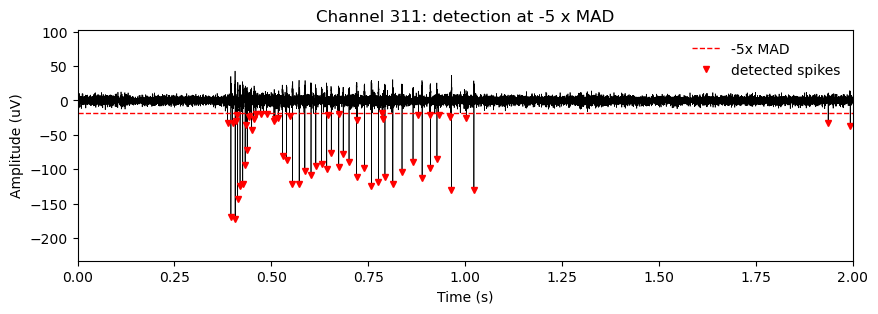

In [10]:
mea.plot_spike_detection(trace, fs, threshold=5)
plt.title(f"Channel {active_ids[0]}: detection at -5 x MAD")
plt.xlim(0, 2); plt.show()

> **🔧 Try it:** change `threshold=5` to `threshold=3` (i.e. −3 x sigma) and
> re-run. Set it back to 5 afterwards.

> **💬 Discuss:** are there more or fewer detected spikes? Look at the extra
> ones: are they spikes or noise? Why is a too-low threshold a problem?

### Detect spikes on more channels and generate raster plots

Detected 2834 spikes on 20 channels


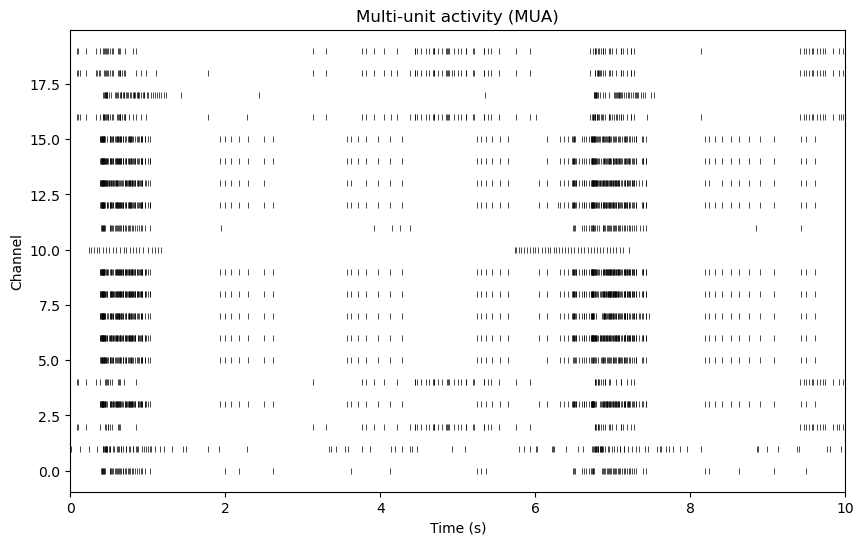

In [11]:
spikes = mea.detect_spikes(filt, fs, channel_ids=active_ids, threshold=5)
print(f"Detected {len(spikes)} spikes on {spikes['channel'].nunique()} channels")
mea.plot_raster(spikes, duration=10)
plt.title("Multi-unit activity (MUA)"); plt.show()

## 5. Firing rate

Firing rate (Hz) = number of spikes / duration (seconds). On MUA this is the
rate of *all* neurons an electrode picks up.

### ✎ Your turn — the firing rate of one channel

`st` below holds the spike times (s) of channel `ch0`, detected in the `duration` = 10 s we loaded.

`len(st)` is the number of spikes.

Compute the firing rate of this channel in Hz.

In [12]:
duration = 10.0
ch0 = active_ids[0]
st = spikes.loc[spikes["channel"] == ch0, "time"].to_numpy()   # spike times (s)

# TODO: replace the 0.0 with the firing rate of channel ch0, in Hz.
rate = 0.0

print(f"channel {ch0}: {rate:.2f} Hz")
mea.check(rate, mea.firing_rate(st, duration), hint="rate = len(st) / duration")

channel 311: 0.00 Hz
[X] not quite yet.
   hint: rate = len(st) / duration
   you got: 0.0
   expected ~ 14.7


False

## 6. Activity map — *where* on the array is it active?

So far we detected on 20 channels. For the map we detect on **all** recorded
electrodes, over the first 5 s (this takes ~10 s: the data are read and
filtered 100 channels at a time). Each electrode is then coloured by its firing
rate at its position on the array; grey electrodes detected no spike. On the
left, the **raster** of the same 5 s: one row per channel, ordered by the
electrode's y position (bottom to top), so the rows run in roughly the same
order as the map.

21990 spikes on 983 of 1002 electrodes


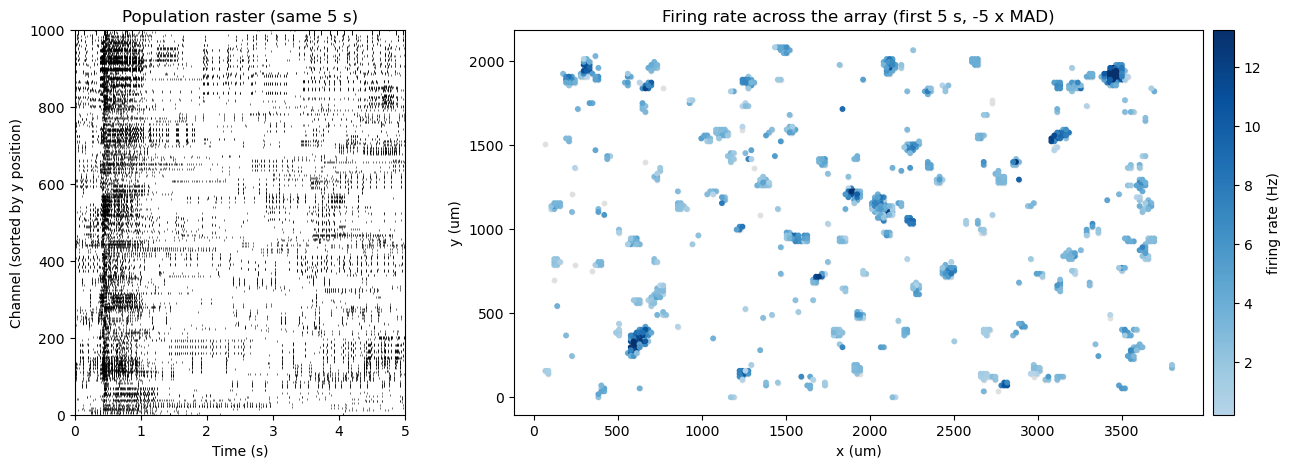

In [13]:
t_map = 5.0                                                    # seconds
spikes_all = mea.detect_spikes_recording(recording, t_start=0, duration=t_map, threshold=5)
rates_all = mea.firing_rate_per_channel(spikes_all, t_map)      # Hz, active channels only
print(f"{len(spikes_all)} spikes on {len(rates_all)} of {recording.get_num_channels()} electrodes")

fig, (ax_r, ax_m) = plt.subplots(1, 2, figsize=(15, 5), width_ratios=[1, 2.2])
mea.plot_activity_map(recording, rates_all.values, channel_ids=rates_all.index.values,
                      ax=ax_m, cmap=mea.sequential_cmap(), s=10,
                      show_all=True, robust=True, label="firing rate (Hz)")
ax_m.set_title(f"Firing rate across the array (first {t_map:g} s, -5 x MAD)")
mea.plot_population_raster(spikes_all, recording, t_map, ax=ax_r, match=ax_m)
ax_r.set_title("Population raster (same 5 s)"); plt.show()

> **💬 Discuss:** is the activity spread evenly over the array, or concentrated
> in a region? Compare with the online spike-rate map in Part 0: do your own
> detection and the chip's online detection agree? What might the pattern mean
> biologically?